# Held-out evaluation and capture inference
Run after notebook 02 completes. This reads its best checkpoint and evaluates the untouched test split once. Do not tune settings on test results; use validation or a fresh test set for subsequent experiments.

The operating threshold is fixed at 0.25 before testing. Per-class recall here requires the correct class and bounding-box IoU >= 0.50. Negative false-positive rate is the fraction of negative images with any detection. Frame-level metrics are correlated within clips; they are a demo check, not evidence of broad real-world coverage. Other MIDV document types are the only negative scenes available here.

The inference helper returns document type, detector confidence and a bounding box. Detector confidence is not a capture-quality percentage. Saving/uploading and reliable quality scoring still require app integration and additional real camera data.


In [1]:
from pathlib import Path
import json
from collections import Counter
import numpy as np
import torch
from ultralytics import YOLO

PROJECT = Path('/home/joe/PycharmProjects/id-capture')
DATA = PROJECT / 'training/data/midv500_yolo'
pointer = json.loads((DATA / 'latest_run.json').read_text())
BEST = Path(pointer['best'])
assert BEST.is_file(), BEST
assert torch.cuda.is_available(), 'CUDA is required.'
detector = YOLO(str(BEST))
manifest = json.loads((DATA / 'manifest.json').read_text())
test_records = [r for r in manifest['records'] if r['split'] == 'test']
CONF = 0.25
IOU = 0.50
print('Checkpoint:', BEST)
print('GPU:', torch.cuda.get_device_name(0))
print('Held-out images:', len(test_records))
print('Class counts:', dict(Counter(r['class'] for r in test_records)))
metrics = detector.val(data=str(DATA / 'data.yaml'), split='test', device=0,
                       workers=0, imgsz=640, batch=16, plots=True,
                       project=pointer['run_dir'], name='test_evaluation')
print('Test mAP50:', metrics.box.map50)
print('Test mAP50-95:', metrics.box.map)


Checkpoint: /home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt
GPU: NVIDIA GeForce RTX 5060 Ti
Held-out images: 981
Class counts: {1: 294, 0: 192, None: 495}
Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 15850MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 219.0±85.4 MB/s, size: 157.2 KB)
val: Scanning /home/joe/PycharmProjects/id-capture/training/data/midv500_yolo/labels/test... 981 images, 495 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 981/981 3.2Kit/s 0.3s0.0s
val: New cache created: /home/joe/PycharmProjects/id-capture/training/data/midv500_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 9.2it/s 6.8s<0.1s
                   all        981        486      0.912      0.949      0.972      0.947
       driving_

In [2]:
def box_iou(boxes, target):
    overlap = np.maximum(0, np.minimum(boxes[:, 2:], target[2:]) - np.maximum(boxes[:, :2], target[:2]))
    intersection = overlap.prod(axis=1)
    areas = np.maximum(0, boxes[:, 2:] - boxes[:, :2]).prod(axis=1)
    target_area = np.maximum(0, target[2:] - target[:2]).prod()
    return intersection / np.maximum(areas + target_area - intersection, 1e-9)

hits = Counter()
totals = Counter(r['class'] for r in test_records)
negative_fp = 0
correct_types = 0
for offset in range(0, len(test_records), 16):
    batch_records = test_records[offset:offset + 16]
    predictions = detector.predict(source=[r['image'] for r in batch_records], conf=CONF,
                                   device=0, imgsz=640, verbose=False)
    for rec, pred in zip(batch_records, predictions):
        boxes = pred.boxes
        predicted_type = None if len(boxes) == 0 else int(boxes.cls[boxes.conf.argmax()].item())
        correct_types += predicted_type == rec['class']
        if rec['class'] is None:
            negative_fp += len(boxes) > 0
            continue
        values = np.array([float(v) for v in Path(rec['label']).read_text().split()[1:]])
        cx, cy, bw, bh = values
        target = np.array([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2])
        same_class = boxes.cls.cpu().numpy().astype(int) == rec['class']
        if same_class.any():
            hits[rec['class']] += bool((box_iou(boxes.xyxyn.cpu().numpy()[same_class], target) >= IOU).any())
    if offset % 160 == 0:
        print('Evaluated', min(offset + 16, len(test_records)), '/', len(test_records), flush=True)

report = {
    'checkpoint': str(BEST), 'confidence_threshold': CONF, 'iou_threshold': IOU,
    'test_images': len(test_records), 'map50': float(metrics.box.map50), 'map50_95': float(metrics.box.map),
    'driving_licence_recall': hits[0] / totals[0], 'passport_recall': hits[1] / totals[1],
    'negative_false_positive_rate': negative_fp / totals[None],
    'top_detection_type_accuracy': correct_types / len(test_records),
    'always_none_type_accuracy': totals[None] / len(test_records),
}
report['demo_targets_met'] = report['driving_licence_recall'] >= 0.90 and report['passport_recall'] >= 0.90 and report['negative_false_positive_rate'] <= 0.05
print(json.dumps(report, indent=2))
(Path(pointer['run_dir']) / 'test_report.json').write_text(json.dumps(report, indent=2))
print('Always-none baseline: recall 0 for both target classes; negative false-positive rate 0.')


Evaluated 16 / 981
Evaluated 176 / 981
Evaluated 336 / 981
Evaluated 496 / 981
Evaluated 656 / 981
Evaluated 816 / 981
Evaluated 976 / 981
{
  "checkpoint": "/home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt",
  "confidence_threshold": 0.25,
  "iou_threshold": 0.5,
  "test_images": 981,
  "map50": 0.9721499783544212,
  "map50_95": 0.9470770997689881,
  "driving_licence_recall": 0.9947916666666666,
  "passport_recall": 0.9727891156462585,
  "negative_false_positive_rate": 0.20202020202020202,
  "top_detection_type_accuracy": 0.8888888888888888,
  "always_none_type_accuracy": 0.5045871559633027,
  "demo_targets_met": false
}
Always-none baseline: recall 0 for both target classes; negative false-positive rate 0.


{'document_type': 'driving_licence', 'detection_confidence': 0.9278871417045593, 'box_xyxy': [10.269561767578125, 283.0429382324219, 455.72760009765625, 615.4725952148438]}


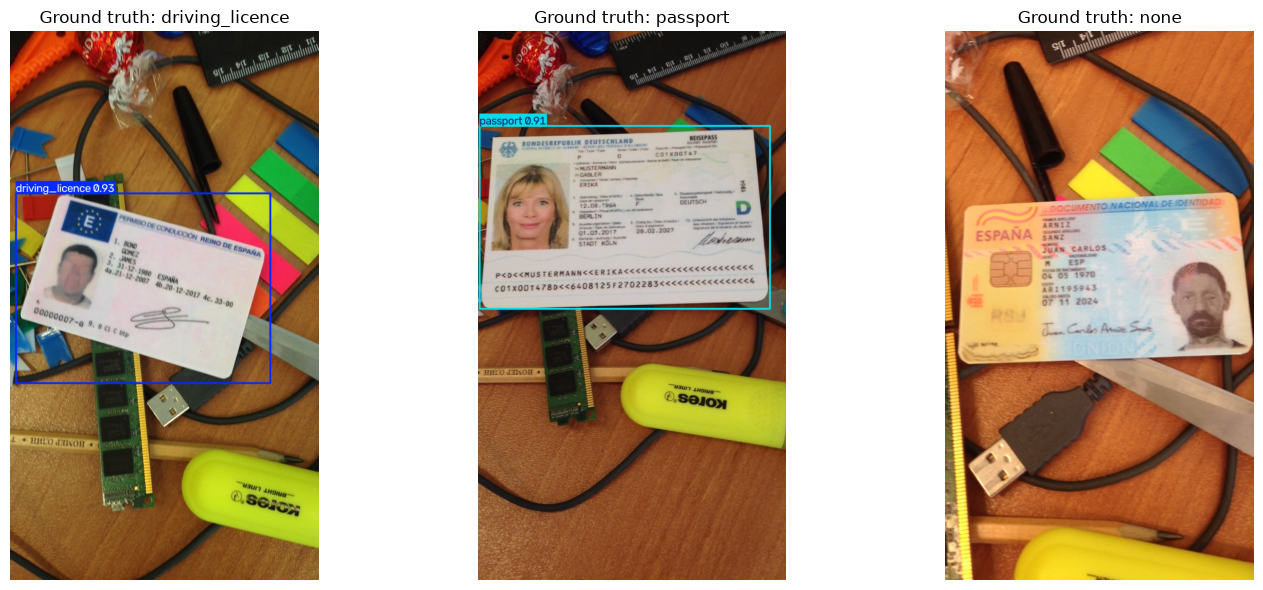

In [3]:
def detect_document(image_path, confidence=CONF):
    result = detector.predict(source=str(image_path), device=0, imgsz=640,
                              conf=confidence, verbose=False)[0]
    if len(result.boxes) == 0:
        return {'document_type': 'none', 'detection_confidence': None, 'box_xyxy': None}
    index = int(result.boxes.conf.argmax().item())
    class_id = int(result.boxes.cls[index].item())
    return {'document_type': result.names[class_id],
            'detection_confidence': float(result.boxes.conf[index].item()),
            'box_xyxy': result.boxes.xyxy[index].cpu().tolist()}

# Replace with your phone capture path when ready.
SAMPLE_IMAGE = next(r['image'] for r in test_records if r['class'] == 0)
print(detect_document(SAMPLE_IMAGE))
import matplotlib.pyplot as plt
example_records = [next(r for r in test_records if r['class'] == cls) for cls in (0, 1, None)]
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, rec in zip(axes, example_records):
    prediction = detector.predict(rec['image'], device=0, conf=CONF, verbose=False)[0]
    ax.imshow(prediction.plot()[..., ::-1])
    ax.set_title('Ground truth: ' + {0: 'driving_licence', 1: 'passport', None: 'none'}[rec['class']])
    ax.axis('off')
plt.tight_layout()
plt.show()


Optional ONNX export after reviewing results:
```python
exported = detector.export(format='onnx', imgsz=640, dynamic=False, simplify=False, opset=17, device=0)
print(exported)
```
Export may require additional packages. Verify exported predictions against the PyTorch checkpoint before integrating with mobile. The present training does not demonstrate capture quality, document authenticity, or unseen-country coverage.
